## 1. Thư viện, cấu hình và đầu ra

In [7]:
from pathlib import Path
from datetime import datetime, timezone
import io, zipfile, json, hashlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, confusion_matrix)
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown

SEED = 42
LABELS = ['Dropout', 'Enrolled', 'Graduate']
N_CANDIDATES = 24
OUT = Path('/kaggle/working/DecisionTree_V2_Outputs') if Path('/kaggle/working').exists() else Path('/mnt/data/DecisionTree_V2_Outputs')
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False})
print('Python:',platform.python_version(),'| sklearn:',sklearn_version,'| Output:',OUT)


Python: 3.13.18 | sklearn: 1.6.1 | Output: /kaggle/working/DecisionTree_V2_Outputs


## 2. Đọc đúng dữ liệu gốc và tái tạo phép chia 80/20 của nhóm

In [8]:
def load_dataset():
    candidates = [
        Path('/kaggle/input/datasets/citrnminhtin/predict-students-dropout-and-academic-success/data.csv'),
        Path('/kaggle/input/predict-students-dropout-and-academic-success/data.csv'),
        Path.cwd() / 'data.csv',
        Path.cwd() / 'data/raw/data.csv',
        Path('/mnt/data/data.csv'),
    ]
    if Path('/kaggle/input').exists():
        candidates += sorted(Path('/kaggle/input').rglob('data.csv'))
    for p in candidates:
        if p.is_file():
            return pd.read_csv(p,sep=';',encoding='utf-8-sig'), p.read_bytes(),str(p)
    for p in [Path('/mnt/data/predict+students+dropout+and+academic+success.zip'), Path.cwd() / 'predict+students+dropout+and+academic+success.zip']:
        if p.is_file():
            with zipfile.ZipFile(p) as z:
                data=z.read('data.csv')
            return pd.read_csv(io.BytesIO(data),sep=';',encoding='utf-8-sig'),data,str(p)+'::data.csv'
    raise FileNotFoundError('Chưa thấy data.csv. Hãy Add Input dataset hoặc tải data.csv lên Kaggle.')

raw, raw_bytes, data_source = load_dataset()
raw.columns = raw.columns.str.strip()
assert raw.shape == (4424,37), f'Dataset khác dự kiến: {raw.shape}'
assert 'Target' in raw.columns
assert not raw.columns.duplicated().any()
assert not raw.isna().any().any(), 'Phát hiện dữ liệu khuyết: cần xem lại bản nguồn'
X = raw.drop(columns=['Target']).copy()
y = raw['Target'].copy()
assert set(y.unique()) == set(LABELS)
train_ids, test_ids = train_test_split(np.arange(len(y)),test_size=0.2,
                                      random_state=SEED,stratify=y)
X_train, y_train = X.iloc[train_ids].copy(), y.iloc[train_ids].copy()
cv_outer = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
DATA_SHA256 = hashlib.sha256(raw_bytes).hexdigest()
print('Nguồn:',data_source)
print('Kích thước:',raw.shape,'| Train:',len(train_ids),'| Test không sử dụng:',len(test_ids))
print('SHA256:',DATA_SHA256)
display(y_train.value_counts().reindex(LABELS).to_frame('train_samples'))
pd.DataFrame({'row_id':train_ids}).to_csv(OUT/'train_indices.csv',index=False)
pd.DataFrame({'row_id':test_ids}).to_csv(OUT/'test_indices.csv',index=False)


Nguồn: /kaggle/input/datasets/citrnminhtin/predictstudentsdropoutandacademicsuccess/data.csv
Kích thước: (4424, 37) | Train: 3539 | Test không sử dụng: 885
SHA256: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae


,train_samples
Target,
Dropout,1137
Enrolled,635
Graduate,1767


## 3. Đối chiếu V1 và thiết kế cải tiến

V1 dùng cột số gốc — một số cột là mã danh mục chứ không phải đại lượng có thứ tự. **Thí nghiệm A** dùng One-Hot cho 17 cột phân loại nhưng *giữ nguyên* max_depth=5, min_samples_leaf=10. **Thí nghiệm B** tuning cây có One-Hot, thử `max_depth`, `min_samples_leaf`, `min_samples_split`, `ccp_alpha`, `class_weight` trong giới hạn 24 tổ hợp.

Mọi Pipeline chỉ fit encoder trên phần train tương ứng của mỗi fold. Không khai thác Test để chọn mô hình.

In [9]:
CATEGORICAL = [
    'Marital status','Application mode','Course','Daytime/evening attendance',
    'Previous qualification','Nacionality',"Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs',
    'Debtor','Tuition fees up to date','Gender','Scholarship holder','International'
]
assert len(CATEGORICAL)==17 and set(CATEGORICAL).issubset(X.columns)
NUMERIC = [c for c in X.columns if c not in CATEGORICAL]
assert len(NUMERIC)==19

def encoded_tree(max_depth=5,min_samples_leaf=10):
    prep = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
        ('num', 'passthrough', NUMERIC)
    ], sparse_threshold=0.3)
    return Pipeline([
        ('prep',prep),
        ('clf',DecisionTreeClassifier(criterion='gini',random_state=SEED,
                                      max_depth=max_depth,min_samples_leaf=min_samples_leaf))
    ])

V1 = DecisionTreeClassifier(criterion='gini',max_depth=5,min_samples_leaf=10,random_state=SEED)
ENCODED_FIXED = encoded_tree()
PARAM_GRID = {
    'clf__max_depth':[4,5,6,7,9,None],
    'clf__min_samples_leaf':[5,10,20],
    'clf__min_samples_split':[2,10],
    'clf__ccp_alpha':[0.0,0.0005,0.002],
    'clf__class_weight':[None,'balanced']
}
print('Nhóm đặc trưng:',len(CATEGORICAL),'One-Hot +',len(NUMERIC),'passthrough')
print('V1:',V1)
print('Tuning: RandomizedSearchCV',N_CANDIDATES,'cấu hình / 3-fold inner CV')


Nhóm đặc trưng: 17 One-Hot + 19 passthrough
V1: DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)
Tuning: RandomizedSearchCV 24 cấu hình / 3-fold inner CV


## 4. Nested cross-validation: đánh giá V1, V2 One-Hot và V2 tuning

- **Outer 5 fold**: bộ chia giống V1, dùng để báo cáo kết quả không phụ thuộc việc chọn siêu tham số ở fold đó.
- **Inner 3 fold**: tìm siêu tham số trên phần Train của outer fold; không nhìn validation ngoài.
- V1 và One-Hot cố định được fit trên outer-train. Model tuned fit `best_estimator_` trên outer-train.
- Ghi rõ **Macro-F1 CV trung bình** khác **Macro-F1 OOF gộp**; chỉ số tuning full train về sau cũng khác outer CV.

In [10]:
def metrics(y_true, y_pred):
    prec, rec, f1, support = precision_recall_fscore_support(
        y_true,y_pred,labels=LABELS,zero_division=0)
    return {
        'accuracy': accuracy_score(y_true,y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true,y_pred),
        'macro_f1': f1_score(y_true,y_pred,labels=LABELS,average='macro'),
        'dropout_recall':float(rec[0]),'enrolled_f1':float(f1[1]),
        'graduate_f1':float(f1[2]),
    }

model_names=['DT_V1_raw_fixed','DT_V2_onehot_fixed','DT_V2_nested_tuned']
all_preds={name:np.empty(len(y_train),dtype=object) for name in model_names}
fold_logs=[]; nested_search_logs=[]; fitted_outer=[]; importance_logs=[]
for fold,(fit_pos,valid_pos) in enumerate(cv_outer.split(X_train,y_train),start=1):
    Xt, yt=X_train.iloc[fit_pos],y_train.iloc[fit_pos]
    Xv, yv=X_train.iloc[valid_pos],y_train.iloc[valid_pos]
    base=clone(V1).fit(Xt,yt)
    fixed=clone(ENCODED_FIXED).fit(Xt,yt)
    inner_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+fold)
    search=RandomizedSearchCV(
        estimator=encoded_tree(),param_distributions=PARAM_GRID,
        n_iter=N_CANDIDATES,cv=inner_cv,scoring='f1_macro',
        random_state=SEED,n_jobs=1,return_train_score=True,refit=True
    )
    search.fit(Xt,yt)
    models=[base,fixed,search.best_estimator_]
    for name,m in zip(model_names,models):
        pv=m.predict(Xv)
        all_preds[name][valid_pos]=pv
        score=metrics(yv,pv)
        score_train=metrics(yt,m.predict(Xt))
        fold_logs.append({'model':name,'fold':fold,'n_fit':len(fit_pos),'n_valid':len(valid_pos),
                          'train_macro_f1':score_train['macro_f1'],
                          'valid_macro_f1':score['macro_f1'],
                          'gap_macro_f1':score_train['macro_f1']-score['macro_f1'],
                          'valid_accuracy':score['accuracy'],
                          'valid_balanced_accuracy':score['balanced_accuracy'],
                          'valid_dropout_recall':score['dropout_recall'],
                          'valid_enrolled_f1':score['enrolled_f1']})
    best_config=dict(search.best_params_)
    nested_search_logs.append({'fold':fold,'best_inner_cv_macro_f1':search.best_score_,
                               'best_params':json.dumps(best_config,ensure_ascii=False)})
    fitted_outer.append((fold,search.best_estimator_,Xv,yv))
    # Permutation importance tính trên validation của outer fold, không sử dụng Test.
    perm=permutation_importance(search.best_estimator_,Xv,yv,n_repeats=3,
                                random_state=SEED+fold,scoring='f1_macro',n_jobs=1)
    for feature, imps in zip(X.columns,perm.importances):
        for repeat,value in enumerate(imps,1):
            importance_logs.append({'fold':fold,'feature':feature,'repeat':repeat,
                                    'macro_f1_drop':float(value)})
    print(f'Outer fold {fold}/5 — best inner Macro-F1={search.best_score_:.4f}, '
          f'outer tuned Macro-F1={metrics(yv,all_preds[model_names[2]][valid_pos])["macro_f1"]:.4f}')

fold_df=pd.DataFrame(fold_logs)
fold_df.to_csv(OUT/'fold_metrics_v1_v2.csv',index=False)
pd.DataFrame(nested_search_logs).to_csv(OUT/'nested_fold_best_params.csv',index=False)
pd.DataFrame(importance_logs).to_csv(OUT/'permutation_importance_outer_raw.csv',index=False)
print('Hoàn tất nested CV. Không sử dụng Test.')


Outer fold 1/5 — best inner Macro-F1=0.6570, outer tuned Macro-F1=0.6796
Outer fold 2/5 — best inner Macro-F1=0.6610, outer tuned Macro-F1=0.6673
Outer fold 3/5 — best inner Macro-F1=0.6747, outer tuned Macro-F1=0.6957
Outer fold 4/5 — best inner Macro-F1=0.6769, outer tuned Macro-F1=0.6771
Outer fold 5/5 — best inner Macro-F1=0.6623, outer tuned Macro-F1=0.6716
Hoàn tất nested CV. Không sử dụng Test.


## 5. So sánh theo fold và các chỉ số từng lớp (OOF)

In [11]:
summary=[]; class_rows=[]; pred_rows=[]
for name in model_names:
    d=fold_df[fold_df.model==name]
    p=all_preds[name]
    oof_m=metrics(y_train,p)
    summary.append({'model':name,
       'cv_macro_f1_mean':d.valid_macro_f1.mean(),
       'cv_macro_f1_std_ddof0':d.valid_macro_f1.std(ddof=0),
       'cv_accuracy_mean':d.valid_accuracy.mean(),
       'cv_dropout_recall_mean':d.valid_dropout_recall.mean(),
       'cv_train_macro_f1_mean':d.train_macro_f1.mean(),
       'cv_gap_mean':d.gap_macro_f1.mean(),
       'oof_macro_f1':oof_m['macro_f1'],
       'oof_accuracy':oof_m['accuracy'],
       'oof_dropout_recall':oof_m['dropout_recall'],
       'oof_enrolled_f1':oof_m['enrolled_f1']})
    prec,rec,f1,support=precision_recall_fscore_support(y_train,p,labels=LABELS,zero_division=0)
    for lbl,pv,rv,fv,n in zip(LABELS,prec,rec,f1,support):
        class_rows.append({'model':name,'class':lbl,'precision':pv,'recall':rv,'f1':fv,'support':int(n)})
    for pos, (row_id, yt, yp) in enumerate(zip(train_ids,y_train.to_numpy(),p)):
        pred_rows.append({'model':name,'row_id':int(row_id),'outer_fold':int(pos//len(y_train)) if False else None,
                          'true_label':yt,'predicted_label':yp})

summary_df=pd.DataFrame(summary)
class_df=pd.DataFrame(class_rows)
summary_df.to_csv(OUT/'model_comparison_cv_oof.csv',index=False)
class_df.to_csv(OUT/'class_metrics_oof.csv',index=False)
# Ghi dự đoán OOF theo row_id, không ghi nhãn Test.
fold_by_pos=np.zeros(len(y_train),dtype=int)
for f,(_,vi) in enumerate(cv_outer.split(X_train,y_train),1):
    fold_by_pos[vi]=f
pd.DataFrame({'row_id':train_ids,'outer_fold':fold_by_pos,'y_true':y_train.to_numpy(),
              **{n:all_preds[n] for n in model_names}}).to_csv(OUT/'oof_predictions_v1_v2.csv',index=False)
display(summary_df.round(4))
display(class_df.round(4))


,model,cv_macro_f1_mean,cv_macro_f1_std_ddof0,cv_accuracy_mean,cv_dropout_recall_mean,cv_train_macro_f1_mean,cv_gap_mean,oof_macro_f1,oof_accuracy,oof_dropout_recall,oof_enrolled_f1
0,DT_V1_raw_fixed,0.6472,0.0230,0.7369,0.7010,0.6877,0.0405,0.6488,0.7369,0.7010,0.3607
1,DT_V2_onehot_fixed,0.6586,0.0186,0.7409,0.6983,0.6933,0.0346,0.6598,0.7409,0.6983,0.3922
2,DT_V2_nested_tuned,0.6783,0.0097,0.7358,0.6965,0.7088,0.0305,0.6792,0.7358,0.6966,0.4513


,model,class,precision,recall,f1,support
0,DT_V1_raw_fixed,Dropout,0.8346,0.7010,0.7620,1137
1,DT_V1_raw_fixed,Enrolled,0.4576,0.2976,0.3607,635
2,DT_V1_raw_fixed,Graduate,0.7471,0.9179,0.8238,1767
3,DT_V2_onehot_fixed,Dropout,0.8402,0.6983,0.7627,1137
4,DT_V2_onehot_fixed,Enrolled,0.4817,0.3307,0.3922,635
5,DT_V2_onehot_fixed,Graduate,0.7498,0.9157,0.8245,1767
6,DT_V2_nested_tuned,Dropout,0.8462,0.6966,0.7641,1137
7,DT_V2_nested_tuned,Enrolled,0.4333,0.4709,0.4513,635
8,DT_V2_nested_tuned,Graduate,0.7909,0.8563,0.8223,1767


## 6. Confusion Matrix, cặp nhầm lẫn và các hình minh chứng

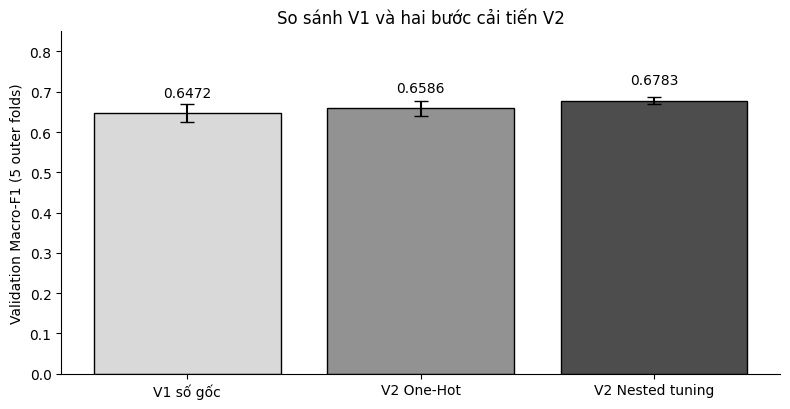

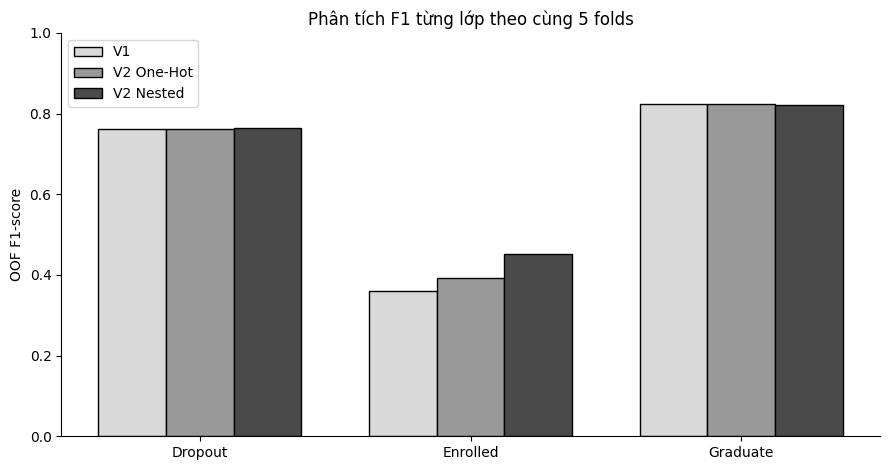

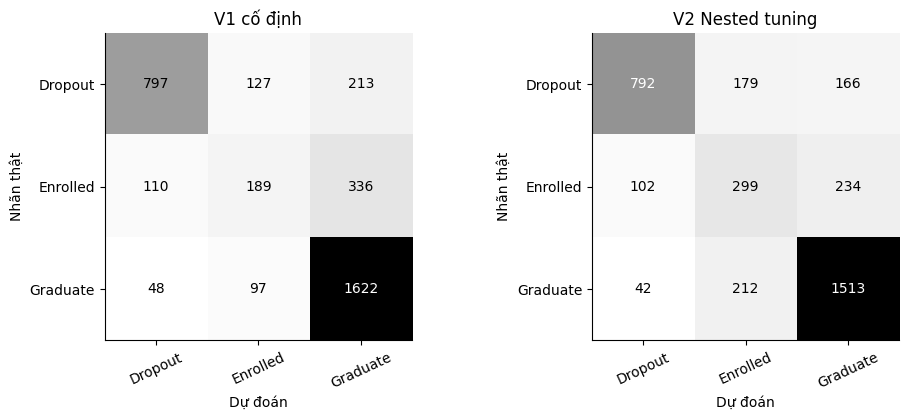

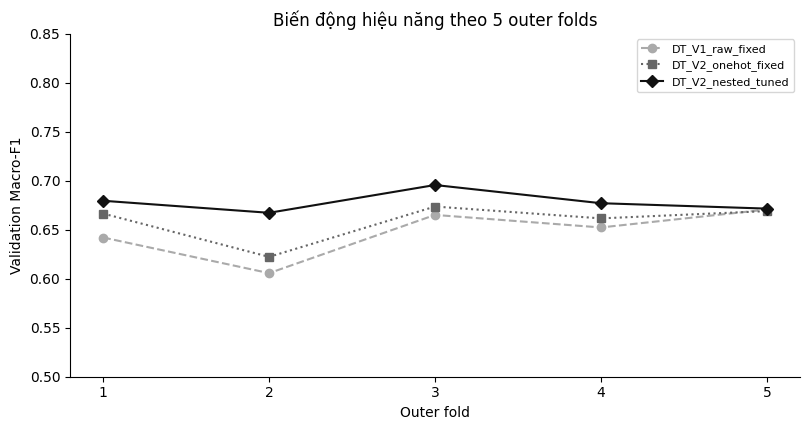

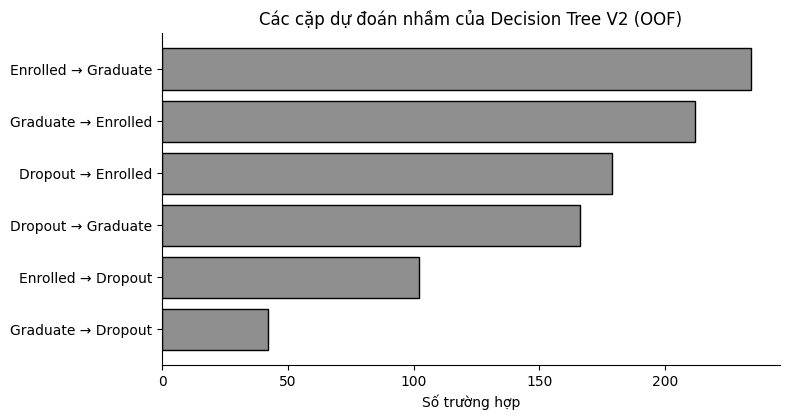

In [12]:
for name in model_names:
    cm=confusion_matrix(y_train,all_preds[name],labels=LABELS)
    pd.DataFrame(cm,index=LABELS,columns=LABELS).to_csv(OUT/f'confusion_{name}.csv')

# Hình 1: macro F1 CV trung bình +/- độ lệch chuẩn ddof=0
fig,ax=plt.subplots(figsize=(8,4.2))
xpos=np.arange(len(model_names))
ax.bar(xpos,summary_df.cv_macro_f1_mean,yerr=summary_df.cv_macro_f1_std_ddof0,
       capsize=5,color=['#d9d9d9','#929292','#4d4d4d'],edgecolor='black')
ax.set_xticks(xpos,['V1 số gốc','V2 One-Hot','V2 Nested tuning']);ax.set_ylim(0,0.85)
ax.set_ylabel('Validation Macro-F1 (5 outer folds)')
ax.set_title('So sánh V1 và hai bước cải tiến V2')
for i,v in enumerate(summary_df.cv_macro_f1_mean): ax.text(i,v+0.04,f'{v:.4f}',ha='center')
fig.tight_layout();fig.savefig(OUT/'01_cv_comparison.png',dpi=180);plt.show();plt.close(fig)

# Hình 2: F1 từng lớp OOF
fig,ax=plt.subplots(figsize=(9,4.8))
xi=np.arange(3);width=.25
for j,name in enumerate(model_names):
    values=class_df[class_df.model==name].set_index('class').loc[LABELS,'f1'].to_numpy()
    ax.bar(xi+(j-1)*width,values,width,color=['#d9d9d9','#999999','#4a4a4a'][j],
           edgecolor='black',label=['V1','V2 One-Hot','V2 Nested'][j])
ax.set_xticks(xi,LABELS);ax.set_ylim(0,1);ax.set_ylabel('OOF F1-score')
ax.set_title('Phân tích F1 từng lớp theo cùng 5 folds');ax.legend()
fig.tight_layout();fig.savefig(OUT/'02_class_f1.png',dpi=180);plt.show();plt.close(fig)

# Hình 3: hai ma trận nhầm lẫn
fig,axs=plt.subplots(1,2,figsize=(10,4.3))
for ax,name,title in zip(axs,[model_names[0],model_names[2]],['V1 cố định','V2 Nested tuning']):
    cm=confusion_matrix(y_train,all_preds[name],labels=LABELS)
    im=ax.imshow(cm,cmap='Greys')
    ax.set_xticks(range(3),LABELS,rotation=25);ax.set_yticks(range(3),LABELS)
    ax.set_xlabel('Dự đoán');ax.set_ylabel('Nhãn thật');ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
fig.tight_layout();fig.savefig(OUT/'03_confusion_v1_v2.png',dpi=180);plt.show();plt.close(fig)

# Hình 4: theo fold
fig,ax=plt.subplots(figsize=(8.2,4.4))
for name,style,color in zip(model_names,['o--','s:','D-'],['#aaaaaa','#666666','#111111']):
    d=fold_df[fold_df.model==name]
    ax.plot(d.fold,d.valid_macro_f1,style,color=color,markersize=6,label=name)
ax.set_xticks([1,2,3,4,5]);ax.set_ylim(0.5,0.85);ax.set_xlabel('Outer fold')
ax.set_ylabel('Validation Macro-F1');ax.set_title('Biến động hiệu năng theo 5 outer folds')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'04_fold_stability.png',dpi=180);plt.show();plt.close(fig)

# Hình 5: cặp nhầm lẫn V2 (không đảo chiều true -> pred)
cm=confusion_matrix(y_train,all_preds[model_names[2]],labels=LABELS)
pairs=[]
for i,a in enumerate(LABELS):
    for j,b in enumerate(LABELS):
        if i!=j:pairs.append({'actual':a,'predicted':b,'count':int(cm[i,j])})
pair_df=pd.DataFrame(pairs).sort_values('count',ascending=False)
pair_df.to_csv(OUT/'error_pairs_v2.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.3))
ax.barh([f'{r.actual} → {r.predicted}' for r in pair_df.itertuples()][::-1],
        pair_df['count'].to_numpy()[::-1],color='#8f8f8f',edgecolor='black')
ax.set_xlabel('Số trường hợp');ax.set_title('Các cặp dự đoán nhầm của Decision Tree V2 (OOF)')
fig.tight_layout();fig.savefig(OUT/'05_error_pairs.png',dpi=180);plt.show();plt.close(fig)


## 7. Tầm quan trọng đặc trưng từ outer-validation folds

Tính **Permutation Importance trên validation của từng outer fold**, bằng cách xáo trộn từng đặc trưng gốc để đo thay đổi Macro-F1. Gộp kết quả trên 5 fold × 3 lần tráo đổi; **không diễn giải như quan hệ nhân quả**. Các đặc trưng có tương quan có thể chia sẻ thông tin, làm giảm mức importance riêng lẻ.

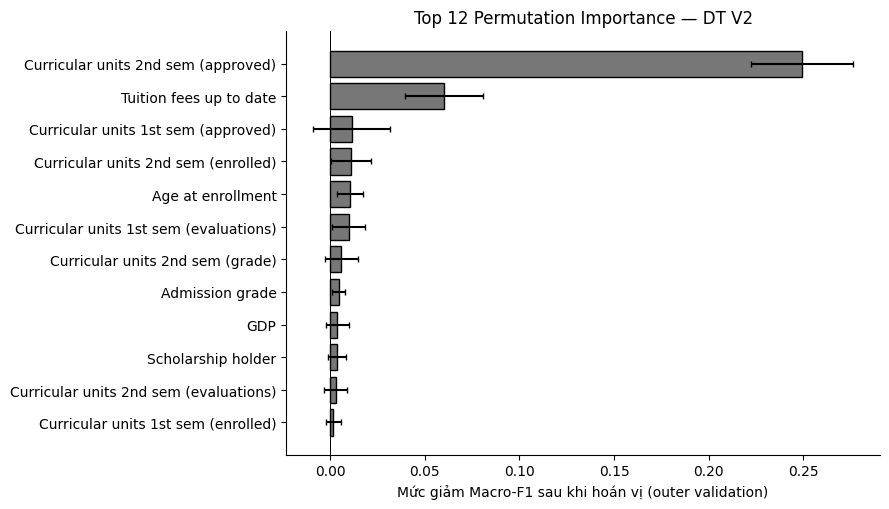

,feature,mean,std
11,Curricular units 2nd sem (approved),0.2493,0.0270
34,Tuition fees up to date,0.0602,0.0207
5,Curricular units 1st sem (approved),0.0114,0.0204
13,Curricular units 2nd sem (enrolled),0.0107,0.0106
1,Age at enrollment,0.0105,0.0069
8,Curricular units 1st sem (evaluations),0.0098,0.0088
15,Curricular units 2nd sem (grade),0.0059,0.0088
0,Admission grade,0.0044,0.0036
23,GDP,0.0038,0.0059
33,Scholarship holder,0.0037,0.0048


In [13]:
imp=pd.DataFrame(importance_logs)
importance_summary=imp.groupby('feature')['macro_f1_drop'].agg(['mean','std']).reset_index()
importance_summary=importance_summary.sort_values('mean',ascending=False)
importance_summary.to_csv(OUT/'feature_importance_outer_cv.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5.2))
top=importance_summary.head(12).iloc[::-1]
ax.barh(top.feature,top['mean'],xerr=top['std'],color='#777777',edgecolor='black',capsize=2)
ax.axvline(0,color='black',linewidth=0.7)
ax.set_xlabel('Mức giảm Macro-F1 sau khi hoán vị (outer validation)')
ax.set_title('Top 12 Permutation Importance — DT V2')
fig.tight_layout();fig.savefig(OUT/'06_feature_importance.png',dpi=180);plt.show();plt.close(fig)
display(importance_summary.head(12).round(4))


## 8. Chọn cấu hình bàn giao bằng CV trên toàn bộ Train (không dùng Test)

Khác **nested outer CV** ở trên: mục này tìm siêu tham số tốt nhất trên toàn bộ Train để huấn luyện model dùng sau này. Điểm tìm kiếm full-train có thể lạc quan nếu dùng làm kết quả đánh giá, vì thế chỉ báo cáo kết quả outer CV ở Chương 4.

In [14]:
search_full=RandomizedSearchCV(
    estimator=encoded_tree(),param_distributions=PARAM_GRID,n_iter=N_CANDIDATES,
    cv=cv_outer,scoring='f1_macro',random_state=SEED,n_jobs=1,
    return_train_score=True,refit=True
)
search_full.fit(X_train,y_train)
full_results=pd.DataFrame(search_full.cv_results_).sort_values(['rank_test_score','mean_test_score'],ascending=[True,False])
full_results[['rank_test_score','mean_test_score','std_test_score','mean_train_score','params']].to_csv(OUT/'tuning_cv_results.csv',index=False)
best_params=search_full.best_params_
model=search_full.best_estimator_  # Fit chỉ trên toàn Train
clf=model.named_steps['clf']
final_config={'model_id':'m02_decision_tree','version':'v2','purpose':'train_only',
              'best_params':best_params,'best_cv_macro_f1':float(search_full.best_score_),
              'max_depth_actual':int(clf.get_depth()),'n_leaves':int(clf.get_n_leaves()),
              'data_sha256':DATA_SHA256,'random_state':SEED,
              'n_train':len(train_ids),'n_test_not_used':len(test_ids),
              'n_candidates':N_CANDIDATES,'outer_folds':5,'inner_folds_nested':3}
(OUT/'best_train_only_config.json').write_text(json.dumps(final_config,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
print('BEST PARAMS (train only):',best_params)
print('CV Macro-F1 từ tìm kiếm full train (KHÔNG phải nested):',round(search_full.best_score_,4))
print('Độ sâu cây fit full Train:',clf.get_depth(),'| số lá:',clf.get_n_leaves())
display(full_results[['rank_test_score','mean_test_score','std_test_score','mean_train_score','params']].head(8))


BEST PARAMS (train only): {'clf__min_samples_split': 10, 'clf__min_samples_leaf': 10, 'clf__max_depth': None, 'clf__class_weight': None, 'clf__ccp_alpha': 0.002}
CV Macro-F1 từ tìm kiếm full train (KHÔNG phải nested): 0.6734
Độ sâu cây fit full Train: 7 | số lá: 19


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
3,1,0.673418,0.020056,0.708834,"{'clf__min_samples_split': 10, 'clf__min_sampl..."
15,1,0.673418,0.020056,0.708834,"{'clf__min_samples_split': 2, 'clf__min_sample..."
12,3,0.671820,0.019847,0.688079,"{'clf__min_samples_split': 2, 'clf__min_sample..."
17,4,0.670778,0.026228,0.745073,"{'clf__min_samples_split': 2, 'clf__min_sample..."
23,5,0.669293,0.027658,0.789407,"{'clf__min_samples_split': 10, 'clf__min_sampl..."
16,6,0.668596,0.024028,0.702815,"{'clf__min_samples_split': 2, 'clf__min_sample..."
4,7,0.668564,0.008046,0.713199,"{'clf__min_samples_split': 10, 'clf__min_sampl..."
1,8,0.668208,0.016248,0.708343,"{'clf__min_samples_split': 10, 'clf__min_sampl..."


## 9. Giải thích cấu trúc cây đã chọn (chỉ trên Train)

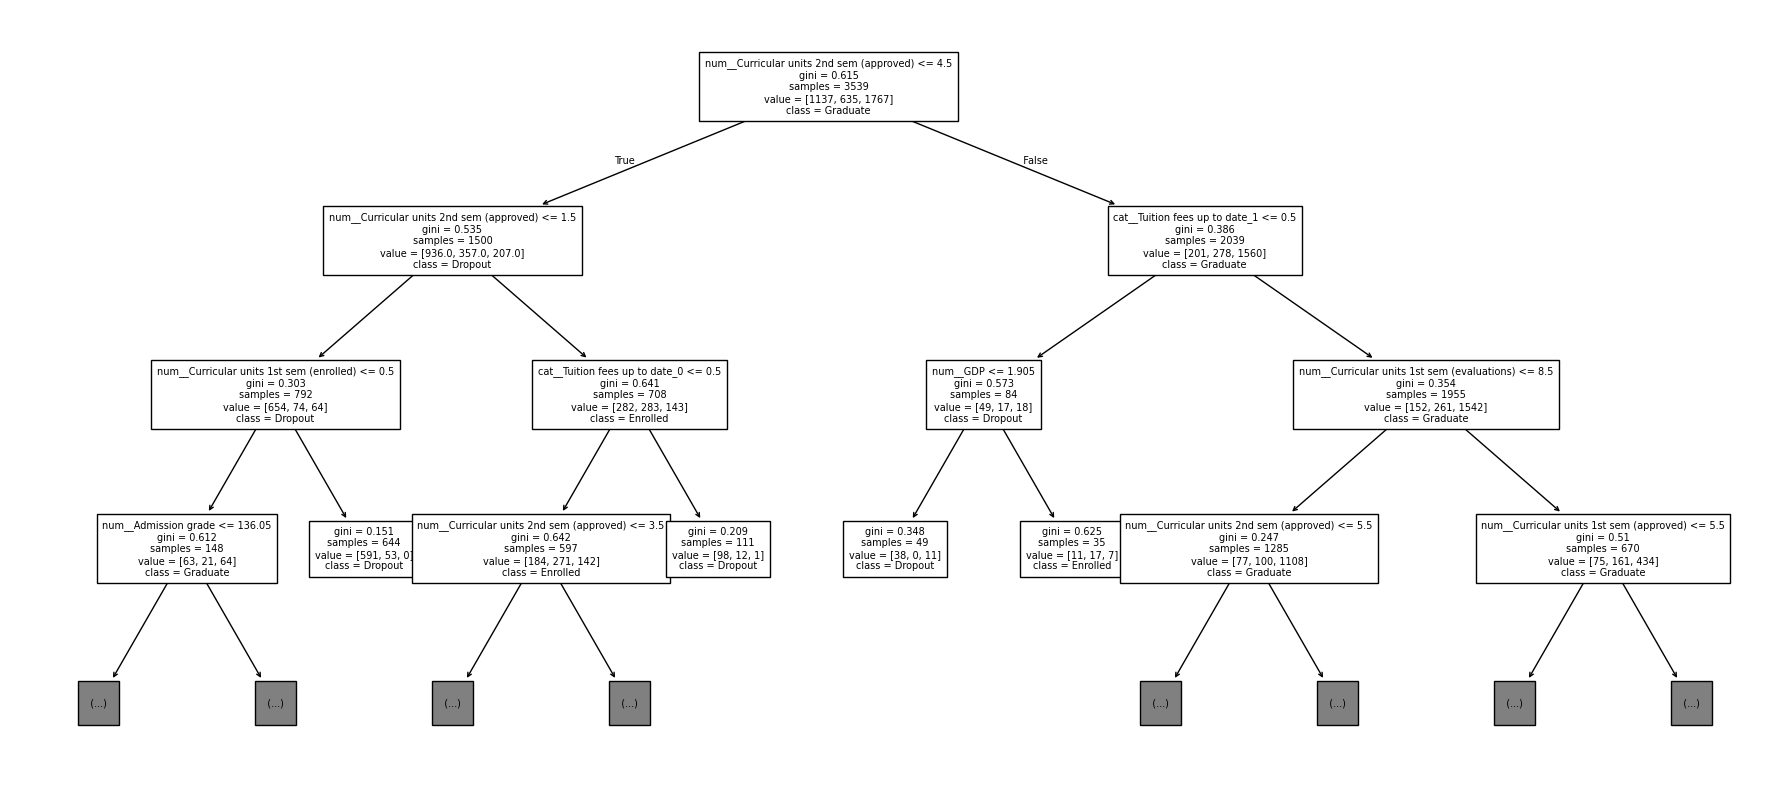

Đã lưu tree_rules_preview.txt và 07_tree_top3_levels.png


In [15]:
transformed_features=model.named_steps['prep'].get_feature_names_out()
fig,ax=plt.subplots(figsize=(18,8))
plot_tree(clf,feature_names=transformed_features,class_names=list(clf.classes_),
          max_depth=3,filled=False,fontsize=7,impurity=True,ax=ax)
fig.tight_layout();fig.savefig(OUT/'07_tree_top3_levels.png',dpi=150);plt.show();plt.close(fig)
rules=export_text(clf,feature_names=list(transformed_features),max_depth=5)
(OUT/'tree_rules_preview.txt').write_text(rules,encoding='utf-8')
print('Đã lưu tree_rules_preview.txt và 07_tree_top3_levels.png')


## 10. Nhật ký thực nghiệm, kiểm tra đối chiếu V1 và xuất ZIP

In [16]:
# So sánh với số OOF V1 đã được người thực hiện bàn giao (nếu cùng thư mục).
for ref in [Path('/mnt/data/oof_predictions (1).csv'),Path.cwd()/'oof_predictions (1).csv']:
    if ref.is_file():
        ref_df=pd.read_csv(ref)
        ours=pd.DataFrame({'row_id':train_ids,'pred':all_preds[model_names[0]]})
        verify=ref_df[['row_id','y_pred']].merge(ours,on='row_id',validate='one_to_one')
        assert len(verify)==3539
        assert (verify['y_pred']==verify['pred']).all(), 'V1 OOF không khớp file tham chiếu'
        print('V1 xác minh 100% với file OOF tham chiếu.');break

run_id='DT_V2_FIXED_SEED42_5OUTER_3INNER_24CAND'
log=[]
for r in summary_df.to_dict('records'):
    log.append({'run_id':run_id,'model':r['model'],'stage':'outer_cv_train_only',
                'data_sha256':DATA_SHA256,'random_state':SEED,
                'outer_folds':5,'inner_folds':3 if r['model']=='DT_V2_nested_tuned' else 0,
                'n_candidates':N_CANDIDATES if r['model']=='DT_V2_nested_tuned' else 0,
                'n_train':len(y_train),'n_test_not_used':len(test_ids),
                'cv_macro_f1_mean':r['cv_macro_f1_mean'],
                'cv_macro_f1_std_ddof0':r['cv_macro_f1_std_ddof0'],
                'oof_macro_f1':r['oof_macro_f1'],'oof_accuracy':r['oof_accuracy'],
                'oof_dropout_recall':r['oof_dropout_recall'],
                'oof_enrolled_f1':r['oof_enrolled_f1'],
                'observations':'V1 fixed' if r['model']==model_names[0] else ('Chỉ thay One-Hot' if r['model']==model_names[1] else 'Nested: tuning chỉ ở inner folds'),
                'conclusion':'Giữ làm mốc' if r['model']==model_names[0] else ('Kiểm tra tác động cách mã hóa' if r['model']==model_names[1] else 'Cải thiện Macro-F1/Enrolled F1; kiểm tra đánh đổi Dropout')})
pd.DataFrame(log).to_csv(OUT/'experiment_log.csv',index=False)
env={'python':platform.python_version(),'sklearn':sklearn_version,'pandas':pd.__version__,
     'numpy':np.__version__,'data_source':data_source,'data_sha256':DATA_SHA256,
     'test_not_evaluated':True}
(OUT/'environment.json').write_text(json.dumps(env,ensure_ascii=False,indent=2),encoding='utf-8')
summary_md='\n'.join(['# Decision Tree V2 — kết quả train-only','',
    'Không dùng Test để tuning hoặc đánh giá. V2 tuned đánh giá theo nested CV (5 outer × 3 inner).','',
    summary_df.round(4).to_string(index=False),'',
    '## Lưu ý','Kết quả CV theo fold khác OOF gộp. Mô hình đã chọn cần đánh giá trên một holdout độc lập trong giai đoạn tiếp theo nếu quy trình nhóm cho phép.',
    'Permutation importance chỉ phản ánh quan hệ dự đoán, không phải nhân quả.'])
(OUT/'README_RESULTS.md').write_text(summary_md,encoding='utf-8')
zip_path=OUT.parent/'DecisionTree_V2_Outputs.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.iterdir()):
        if f.is_file():z.write(f,arcname=f.name)
print('DONE —',len([p for p in OUT.iterdir() if p.is_file()]),'files')
print('ZIP:',zip_path)


DONE — 26 files
ZIP: /kaggle/working/DecisionTree_V2_Outputs.zip
